In [30]:
import numpy as np
import matplotlib.pyplot as plt
from numpy import sqrt,sin,cos,pi,exp
from scipy.special import beta
import numpy as np


N = 256
nu = 1.5

h = 1/N
x = lambda s: s**nu

gamma = 0.02
sigma = 0.005
alpha = sigma**2 / gamma**2

s_grid = np.array([i*h + h/2 for i in range(N)])
t_grid = np.array([i*h for i in range(1,N+1)])

x_grid = [x(s) for s in s_grid]

# Abel Problem
def k(t,s):
    if s<t:
        return 1/sqrt((t-s))
    else:
        return 0

A = np.zeros((N,N))
for i in range(N):
    for j in range(N):
        A[i,j] = h * k(t_grid[i], s_grid[j])


# Ax(s) = y(t)          
y_grid = A @ x_grid

# or the analytical solutions
y = lambda t: t**(nu + 1/2) * beta(1 + nu, 0.5)
y_analytical = [y(t) for t in t_grid]

y2 = lambda t: 3*pi/8 * t**2
y2_analytical = [y2(t) for t in t_grid]

We want to sample our noise $e$

$$
e \sim \mathcal{N}(0,\gamma^2I)
$$

In [31]:
rng = np.random.default_rng(42)

# normal distributed
e = rng.normal(
    loc=0.0,              # mean
    scale=gamma,          # standarddeviation, not the variance!
    size=A.shape[0]       # dimensions
)

y_delta = y_grid + e

Now we want to see the plot:

**Remark:** we are working with the numerical y, in our case 'y_grid'

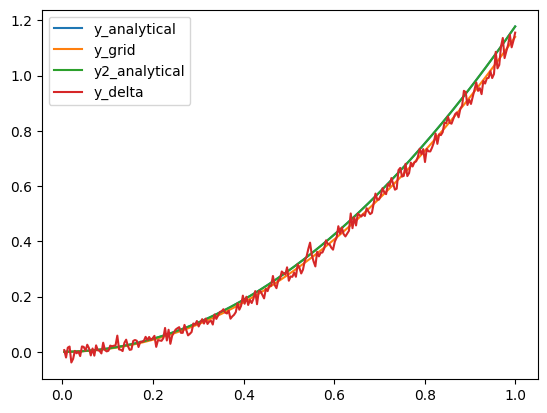

In [32]:
plt.plot(t_grid,y_analytical,label="y_analytical")
plt.plot(t_grid,y_grid,label="y_grid")
plt.plot(t_grid,y2_analytical,label="y2_analytical")
plt.plot(t_grid,y_delta,label="y_delta")

plt.legend()
plt.show()

Now we are applying the Tikhonov regularization

$$
x_{\alpha} = \sum_j \frac{\mu_j^2}{\mu_j^2 + \alpha} \frac{(y^{\delta},y_j)}{\mu_j}x_j
$$

with 100 different noise samples $e \sim \mathcal{N}(0,\gamma^2I)$

[]

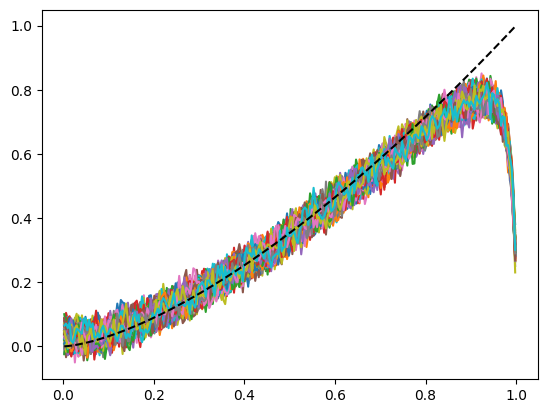

In [33]:
U, mu, Vt = np.linalg.svd(A,compute_uv=True)

rng = np.random.default_rng(42)

#sample mean
x_mean = np.zeros(N)    

#Tikhonov regularisation
for sample in range(100):
    # normal distributed
    e = rng.normal(
        loc=0.0,              # mean
        scale=gamma,          # standarddeviation, not the variance!
        size=A.shape[0]       # dimensions
    )

    y_delta = y_grid + e
    k_top = min(500,N)
        # a_array = 10**np.linspace(-4,1,k_top)

    x_alpha = np.zeros(N)

    for j in range(k_top):
        factor = mu[j] / (mu[j]**2 + alpha)
        x_alpha += factor * np.dot(y_delta, U[:,j]) * Vt[j,:]
    x_mean += x_alpha
    plt.plot(s_grid,x_alpha,label=f"idk")
# plt.legend()
plt.plot(s_grid,x_grid,label="initial x",color='black',linestyle="--")
plt.plot()



sample mean

$$
x_{\alpha} = \frac{1}{100} \sum_{i=1}^{100} x_{\alpha}^{(i)}
$$

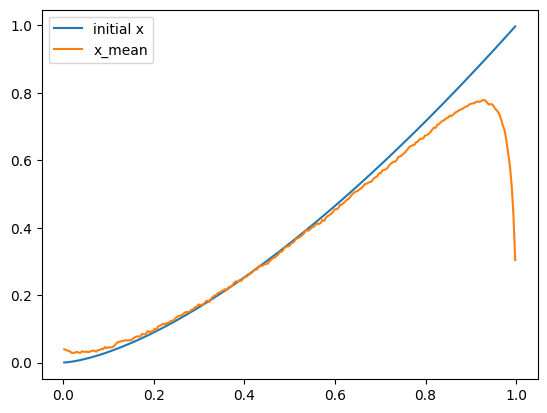

In [34]:
x_mean = x_mean/100
plt.plot(s_grid,x_grid,label="initial x")
plt.plot(s_grid,x_mean,label="x_mean")
plt.legend()
plt.show()